# TT-30 — ARIMA / SARIMA: dự báo lượng khách tháng để lập kế hoạch nhân sự

**Bài toán.** Dự báo lượng khách 1–24 tháng tới **kèm khoảng dự báo** để tuyển nhân viên thời vụ (trước 6 tuần), đặt
nguyên liệu và lập kế hoạch dòng tiền. Luyện trên **AirPassengers**: 144 tháng (1949–1960) khách hàng không quốc tế,
đơn vị nghìn khách.

**Quy trình Box-Jenkins:** ① nhìn → ② làm dừng (ADF) → ③ định bậc (ACF/PACF) → ④ ước lượng → ⑤ kiểm tra phần dư
(Ljung-Box) → ⑥ dự báo kèm khoảng tin cậy.

**Cách đánh giá:** 120 tháng train (1949–1958), 24 tháng test (1959–1960). Mọi mô hình, kể cả baseline, dự báo **một
lần 24 tháng** từ tháng 12/1958, không nhìn giá trị test nào. Chọn bậc chỉ dùng train. Notebook chạy ~5 phút.

In [1]:
%matplotlib inline
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path("..").resolve() / "src"))

import numpy as np
import pandas as pd
from IPython.display import Image, display

import stationarity as S
import train as T

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.width", 200)
R = T.REPORTS_DIR
y = S.load()
print(len(y), "thang:", y.index[0].strftime("%m/%Y"), "->", y.index[-1].strftime("%m/%Y"))

144 thang: 01/1949 -> 12/1960


## 1–3. Nhìn chuỗi: trend, mùa vụ, biên độ phình dần → mô hình nhân tính

**Logic code (`run_look`):** vẽ chuỗi gốc và log. Biên độ mùa vụ mỗi năm = max − min trong năm, ở thang gốc và thang
log. `seasonal_decompose(period=12)` theo 2 kiểu: kiểu nào đúng thì phần dư **không** còn to/nhỏ theo mức của chuỗi.

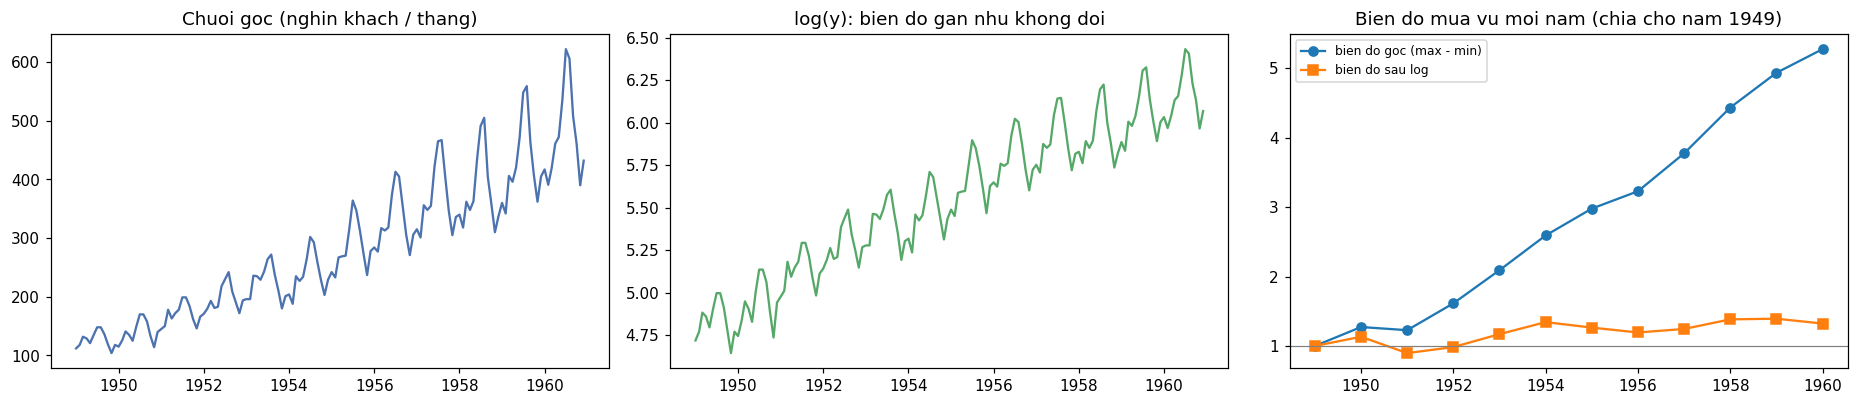

nam,1949,1950,1951,1952,1953,1954,1955,1956,1957,1958,1959,1960
trung_binh_nam,126.6670,139.6670,170.1670,197.0000,225.0000,238.9170,284.0000,328.2500,368.4170,381.0000,428.3330,476.1670
bien_do_goc,44.0000,56.0000,54.0000,71.0000,92.0000,114.0000,131.0000,142.0000,166.0000,195.0000,217.0000,232.0000
bien_do_tuong_doi,0.3470,0.4010,0.3170,0.3600,0.4090,0.4770,0.4610,0.4330,0.4510,0.5120,0.5070,0.4870
bien_do_log,0.3530,0.4000,0.3170,0.3470,0.4130,0.4740,0.4460,0.4210,0.4390,0.4880,0.4910,0.4670


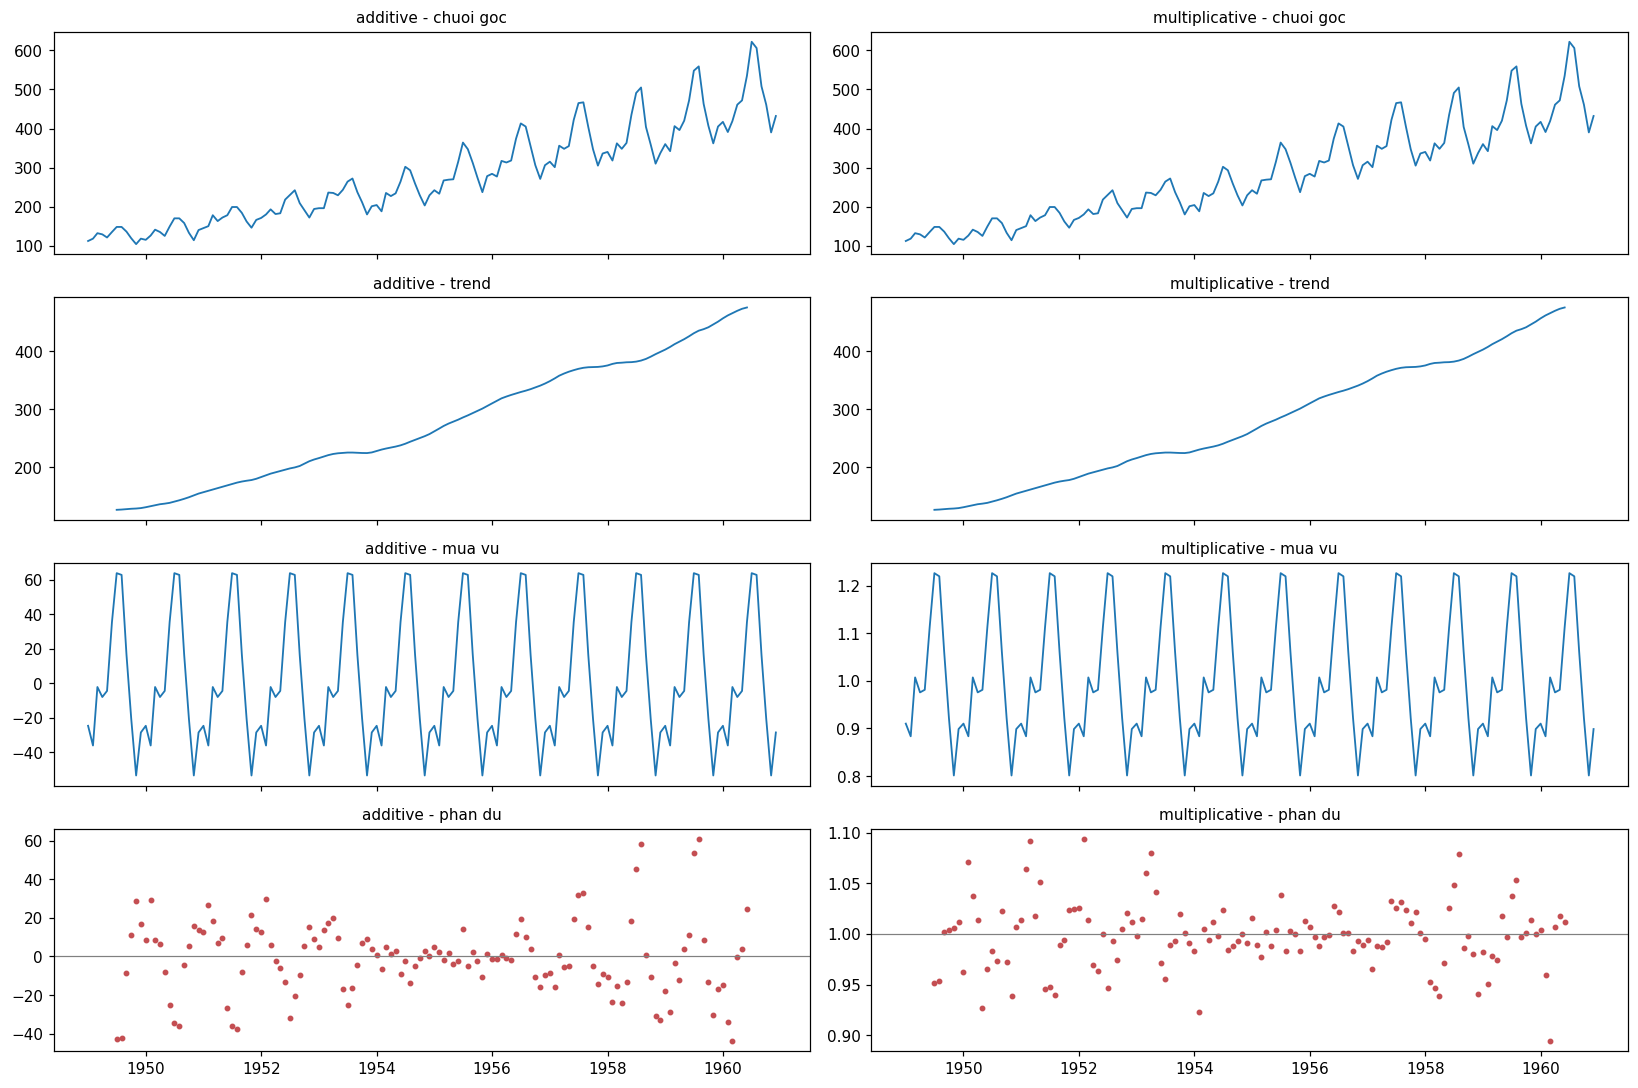

,kieu,tuong_quan_do_lech_phan_du_vs_muc,do_lech_phan_du_nam_dau,do_lech_phan_du_nam_cuoi
0,additive,0.1601,30.5264,25.4305
1,multiplicative,-0.0718,0.0278,0.0479


In [2]:
look = T.run_look(y)
display(Image(R / "chuoi_goc_va_log.png"))
display(look["bien_do"].round(3).T)
display(Image(R / "decompose.png"))
display(look["decompose"])

**Đọc kết quả:**

* **Trend tăng** gần tuyến tính (112 → 432 nghìn khách) và **mùa vụ 12 tháng** rõ: đỉnh tháng 7–8 (hè), đáy tháng 11.
* **Biên độ mùa vụ phình theo trend:** max − min mỗi năm tăng từ 44 (1949) lên 232 (1960), gấp **5,3 lần**, trong khi biên
  độ *tương đối* (chia cho trung bình năm) chỉ đi từ 0,35 lên 0,49. Mùa vụ tỉ lệ với mức của chuỗi, nên đây là mô hình
  **nhân tính**.
* **Sau log**, biên độ chỉ còn tăng 1,3 lần (0,35 → 0,47) thay vì 5,3 lần. Log giải quyết phần lớn nhưng chưa hoàn
  toàn (Box-Cox với λ khác 0 có thể ổn định tốt hơn; ở đây giữ log theo đề).
* **Phân rã:** phần dư của `additive` **xoè ra hai đầu** (±40–60 năm 1949–1951 và 1958–1960, gần 0 giữa chuỗi): mùa vụ
  cộng tính cố định không khớp năm đầu lẫn năm cuối. Phần dư `multiplicative` dao động đều quanh 1 (±5–10%). Tương quan
  giữa độ lệch phần dư mỗi năm và mức chuỗi: additive **+0,16**, multiplicative **−0,07**. → **Chọn nhân tính → lấy log.**

## 4–5. Làm dừng: ADF trên 6 phiên bản chuỗi, rồi ACF / PACF

**Logic code (`stationarity.adf_table`):** `adfuller(s, autolag="AIC")`. H0 của ADF là **không dừng**, nên p < 0,05 mới
kết luận dừng. Thêm KPSS làm đối chứng (H0 ngược lại: dừng). statsmodels chặn p của KPSS trong [0,01; 0,10].

,phien_ban,so_diem,ADF_p,ADF_ket_luan,so_lag_ADF,KPSS_p,KPSS_ket_luan
0,goc,144,0.9919,KHONG DUNG,13,0.0100,KHONG DUNG
1,log,144,0.4224,KHONG DUNG,13,0.0100,KHONG DUNG
2,log + diff(1),143,0.0711,KHONG DUNG,14,0.1000,DUNG
3,log + diff(12),132,0.0724,KHONG DUNG,12,0.1000,DUNG
4,log + diff(1) + diff(12),131,0.0002,DUNG,12,0.1000,DUNG
5,goc + diff(1) + diff(12),131,0.0000,DUNG,0,0.1000,DUNG


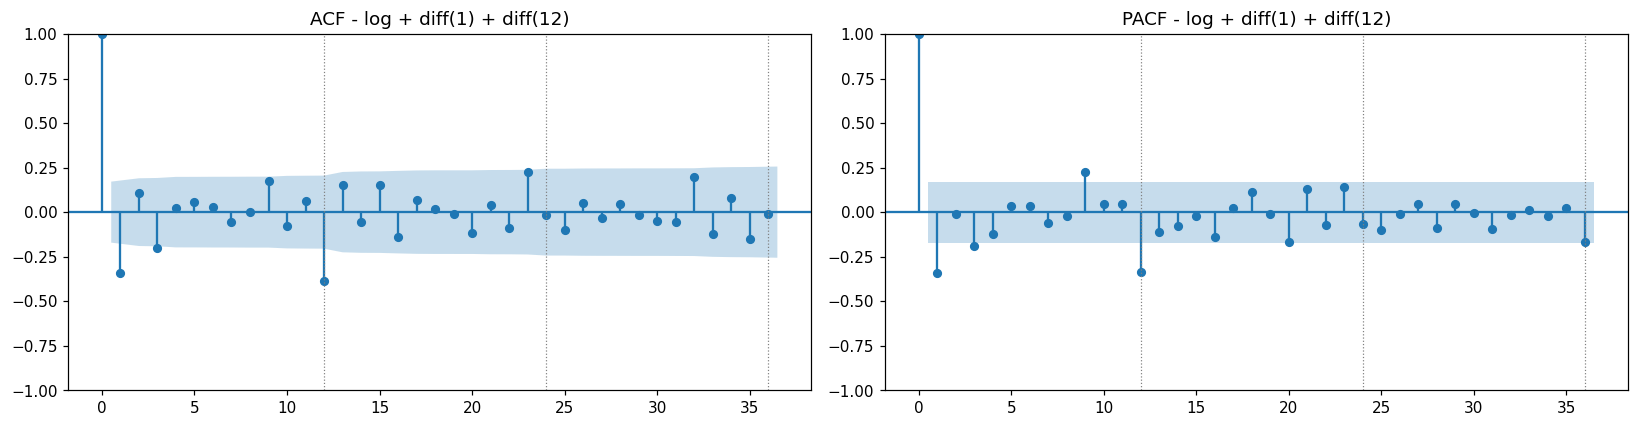

Nguong 95%: 0.171


,lag,ACF,PACF,ACF_vuot_nguong,PACF_vuot_nguong
0,1,-0.3411,-0.3411,True,True
2,3,-0.2021,-0.1927,True,True
8,9,0.1764,0.2256,True,True
11,12,-0.3866,-0.3387,True,True
22,23,0.2233,0.1429,True,False
31,32,0.1957,-0.0153,True,False


In [3]:
st = T.run_stationarity(y)
display(st["adf"])
display(Image(R / "acf_pacf.png"))
a = st["acf_pacf"]
print("Nguong 95%:", round(1.96 / np.sqrt(131), 3))
display(a[a["ACF_vuot_nguong"] | a["PACF_vuot_nguong"]])

**Đọc kết quả, bảng ADF:**

| Phiên bản | ADF p | Kết luận |
|---|---:|---|
| gốc | 0,992 | không dừng |
| log | 0,422 | không dừng (vẫn còn trend) |
| log + diff(1) | 0,071 | **sát ngưỡng**, chưa dừng (còn mùa vụ) |
| log + diff(12) | 0,072 | sát ngưỡng, chưa dừng (còn trend dư) |
| **log + diff(1) + diff(12)** | **0,0002** | **dừng** ✅ |

→ **d = 1, D = 1.** KPSS đồng ý từ "log + diff(1)" trở đi (p = 0,10, không bác bỏ tính dừng), nhưng ADF thì chưa. Khi
2 kiểm định lệch nhau ở sát ngưỡng, sai phân thêm theo mùa là hợp lý vì mùa vụ nhìn bằng mắt đã rất rõ.

**ACF / PACF của log + diff(1) + diff(12)** (ngưỡng ±0,171):

* **ACF:** vượt ngưỡng rõ ở **lag 1 (−0,34)** và **lag 12 (−0,39)** rồi **tắt hẳn** (lag 13, 24, 36 đều trong ngưỡng).
  ACF tắt sau lag q → **MA(1)**. Tắt sau lag 12 ở tầng mùa → **SMA(1)**.
* **PACF:** cũng −0,34 ở lag 1 và −0,34 ở lag 12, nhưng sau đó **giảm dần** (lag 24, 36 nhỏ dần) thay vì tắt hẳn. Đây
  là dấu hiệu của MA, không phải AR.
* Lag 3 (−0,20) và lag 9 (+0,18) chỉ nhỉnh hơn ngưỡng một chút. Với 36 lag × 5% thì kỳ vọng ~2 lag vượt ngưỡng do ngẫu
  nhiên, nên bỏ qua.

→ **Đề xuất thủ công: SARIMA(0,1,1)(0,1,1,12)**, chính là mô hình "airline" kinh điển của Box & Jenkins cho bộ này.

## 6–7. Chia train/test và 2 baseline

```python
train, test = y[:120], y[120:144]                    # 1949-1958 | 1959-1960
naive          = [train[-1]] * 24                     # lap lai thang 12/1958
seasonal_naive = np.tile(train[-12:], 2)              # lap lai 12 thang cuoi cua 1958
# (them) seasonal naive + drift = seasonal_naive x (toc do tang TB nam qua nam cua train)^so_nam
```

In [4]:
train, test = T.split(y)
base = T.baselines(train, T.H)
pd.DataFrame({k: T.metrics(test, v) for k, v in base.items()}).T

,MAPE_%,MAE,RMSE,sai_lech_TB_%
Naive (thang truoc),23.5775,115.2500,137.3290,-23.5775
Seasonal naive (cung thang nam ngoai),15.5234,71.2500,76.9946,-15.5234
Seasonal naive + drift (them),3.0056,13.2788,17.0159,1.2414


**Đọc kết quả:** Naive MAPE **23,6%**, seasonal naive **15,5%**. Cả 2 đều **dự báo thiếu** (sai lệch TB = −MAPE) vì
không có trend: 1959–1960 cao hơn 1958 nhưng baseline lặp lại 1958. Baseline thêm "seasonal naive + **drift**" (nhân với
tốc độ tăng TB 12,9%/năm của train) chỉ sai **3,0%**. Đây là đối thủ khó nhất (xem phần backtest).

## 8. SARIMA thủ công

**Logic code (`fit_sarima`, `run_manual`):**

```python
fit = SARIMAX(np.log(train), order=(0,1,1), seasonal_order=(0,1,1,12)).fit(disp=False)
f   = fit.get_forecast(24)
du_bao = np.exp(f.predicted_mean); khoang_95 = np.exp(f.conf_int(alpha=0.05))   # exp() ve thang so khach
```

⚠️ **Không** dùng `enforce_stationarity=False, enforce_invertibility=False` như code mẫu của đề (lý do ở bước 9). So 3
mô hình: bậc thủ công, bậc gợi ý của đề (1,1,1)(1,1,1,12), và bậc thủ công nhưng **không lấy log**.

In [5]:
man_t, man = T.run_manual(train, test)
man_t

,mo_hinh,order,seasonal_order,log,AIC,BIC,MAPE_%,MAE,RMSE,sai_lech_TB_%,phu_95_%,phu_80_%,LjungBox_p_lag12,LjungBox_p_lag24,thoi_gian_fit_s
0,"SARIMA thu cong (0,1,1)(0,1,1,12) - log","(0, 1, 1)","(0, 1, 1, 12)",True,-389.0097,-380.9913,8.5154,39.4431,43.1793,-8.5154,100.0000,95.8333,0.9124,0.8036,1.8325
1,"SARIMA cua de (1,1,1)(1,1,1,12) - log","(1, 1, 1)","(1, 1, 1, 12)",True,-385.4405,-372.0764,7.8253,36.2534,40.0012,-7.8253,100.0000,91.6667,0.9552,0.8646,2.3711
2,"SARIMA (0,1,1)(0,1,1,12) - KHONG log","(0, 1, 1)","(0, 1, 1, 12)",False,NaN,NaN,14.4374,66.4025,71.9600,-14.4374,50.0000,8.3333,0.8075,0.1584,0.2377


**Đọc kết quả:**

| | AIC | MAPE test | Sai lệch TB | Phủ 95% | Phủ 80% | Ljung-Box p (12 / 24) |
|---|---:|---:|---:|---:|---:|---:|
| **(0,1,1)(0,1,1,12) log** | **−389,0** | 8,5% | −8,5% | 100% | 95,8% | 0,91 / 0,80 |
| (1,1,1)(1,1,1,12) log (đề) | −385,4 | 7,8% | −7,8% | 100% | 91,7% | 0,96 / 0,86 |
| (0,1,1)(0,1,1,12) **không log** | — | **14,4%** | −14,4% | **50%** | **8%** | 0,81 / 0,16 |

* ✅ SARIMA log **thắng seasonal naive** (8,5% so với 15,5%).
* Mô hình của đề có thêm 2 tham số (AR(1), SAR(1)) nhưng AIC kém hơn (−385,4 so với −389,0). MAPE test tốt hơn 0,7 điểm
  chỉ trên một mẫu 24 điểm, nên không đủ để chọn nó (xem bước 9: MAPE test thay đổi lung tung giữa các bậc).
* ❌ **Không log thì sai gấp 1,7 lần và khoảng dự báo vô dụng:** mô hình cộng tính giữ biên độ mùa vụ của train, không
  phình theo trend, nên khoảng 95% chỉ phủ 50% giá trị thật, khoảng 80% chỉ phủ 8%.

## 9. Dò tự động theo AIC, và cái bẫy `enforce_*=False`

**Logic code (`run_grid`):** p, q, P, Q ∈ {0, 1, 2}, d = D = 1 cố định theo ADF → 81 mô hình, chọn AIC thấp nhất trên
train. AIC chỉ so sánh được giữa các mô hình có **cùng** mức sai phân (cùng dữ liệu đầu vào), nên không quét d, D.

Trước đó, `run_aic_trap` fit cùng 5 mô hình với `enforce_*=False` (code của đề) và `True` (mặc định).

In [6]:
trap = T.run_aic_trap(train, test)
display(trap)
grid_t, grid_run = T.run_grid(train, test)
display(grid_t.head(10))
print("MAPE test cua 81 mo hinh:"); display(grid_t["MAPE_test_%"].describe().to_frame().T)

,mo_hinh,enforce,so_diem_bo_dau,so_diem_tinh_likelihood,loglik,AIC,MAPE_test_%,hang_AIC_trong_nhom
0,"(1, 1, 0)(0, 1, 0, 12)",False,14,106,181.9887,-359.9773,14.7346,1
1,"(1, 1, 0)(0, 1, 0, 12)",True,13,107,183.7865,-363.5730,14.7346,4
2,"(2, 1, 2)(0, 1, 0, 12)",False,16,104,180.3522,-350.7043,8.5368,2
3,"(2, 1, 2)(0, 1, 0, 12)",True,13,107,185.5960,-361.1920,13.7640,5
4,"(0, 1, 1)(0, 1, 1, 12)",False,27,93,173.3463,-340.6927,8.4983,3
5,"(0, 1, 1)(0, 1, 1, 12)",True,13,107,197.5049,-389.0097,8.5154,1
6,"(1, 1, 1)(1, 1, 1, 12)",False,27,93,171.3109,-332.6217,9.4841,5
7,"(1, 1, 1)(1, 1, 1, 12)",True,13,107,197.7203,-385.4405,7.8253,3
8,"(0, 1, 1)(1, 1, 1, 12)",False,27,93,171.3043,-334.6087,9.6698,4
9,"(0, 1, 1)(1, 1, 1, 12)",True,13,107,197.6101,-387.2201,8.4129,2


[grid] 81 mo hinh trong 223s | AIC tot nhat (0, 1, 1)(0, 1, 1, 12) AIC=-389.0 MAPE test=8.52%


,order,seasonal_order,AIC,BIC,MAPE_test_%,hang_AIC,hang_MAPE_test
0,"(0, 1, 1)","(0, 1, 1, 12)",-389.0097,-380.9913,8.5154,1,30
1,"(1, 1, 0)","(0, 1, 1, 12)",-388.6432,-380.6247,9.0228,2,50
2,"(1, 1, 1)","(0, 1, 1, 12)",-387.2788,-376.5875,7.7859,3,13
3,"(0, 1, 1)","(0, 1, 2, 12)",-387.2539,-376.5626,8.3848,4,26
4,"(0, 1, 1)","(1, 1, 1, 12)",-387.2201,-376.5288,8.4129,5,27
5,"(0, 1, 2)","(0, 1, 1, 12)",-387.0654,-376.3741,8.3587,6,23
6,"(1, 1, 0)","(0, 1, 2, 12)",-386.7916,-376.1003,8.9468,7,46
7,"(1, 1, 0)","(1, 1, 1, 12)",-386.7748,-376.0835,8.9650,8,47
8,"(2, 1, 0)","(0, 1, 1, 12)",-386.6579,-375.9666,8.9871,9,49
9,"(2, 1, 1)","(0, 1, 1, 12)",-386.6123,-373.2482,6.9164,10,2


MAPE test cua 81 mo hinh:


,count,mean,std,min,25%,50%,75%,max
MAPE_test_%,81.0000,9.3099,1.9621,6.4433,8.3450,8.8651,9.4588,15.1525


**Đọc kết quả:**

**Bẫy `enforce_stationarity=False, enforce_invertibility=False`:** khi tắt ràng buộc, statsmodels khởi tạo bộ lọc
Kalman kiểu "diffuse" và **bỏ qua số quan sát đầu = số trạng thái của mô hình**. Con số này khác nhau theo bậc:

| Mô hình | enforce=False: số điểm tính likelihood | AIC | Hạng | enforce=True: số điểm | AIC | Hạng |
|---|---:|---:|---:|---:|---:|---:|
| (1,1,0)(0,1,0,12) | 106 | −360,0 | **1** | 107 | −363,6 | 4 |
| (2,1,2)(0,1,0,12) | 104 | −350,7 | 2 | 107 | −361,2 | 5 |
| (0,1,1)(0,1,1,12) | **93** | −340,7 | 3 | 107 | **−389,0** | **1** |
| (1,1,1)(1,1,1,12) | 93 | −332,6 | 5 | 107 | −385,4 | 3 |

Với `False`, mô hình có thành phần mùa bị tính likelihood trên **13 điểm ít hơn**, nên AIC "thua" một cách giả tạo, và
AIC chọn ra (1,1,0)(0,1,0,12): **không có thành phần mùa**, phần dư còn tự tương quan ở lag 12 (Ljung-Box p = 0,001),
MAPE 14,7% (ngang seasonal naive). Với `True`, mọi mô hình đều bỏ đúng 13 điểm (1 + 12 của sai phân) nên AIC công bằng.

**Kết quả lưới (enforce=True):** AIC tốt nhất = **(0,1,1)(0,1,1,12)**, **trùng với bậc chọn thủ công** từ ACF/PACF. Top
10 theo AIC đều có SMA(1) hoặc SMA(2), và AIC chỉ chênh nhau ≤ 2,4.

**Đừng chọn theo MAPE test:** 81 mô hình có MAPE test từ 6,4% đến 15,2%. Mô hình có MAPE test thấp nhất,
(2,1,1)(0,1,0,12), xếp **hạng 75/81** theo AIC: may mắn trên 24 điểm, không phải mô hình tốt.

**Mô hình cuối: SARIMA(0,1,1)(0,1,1,12) trên log** (AIC thấp nhất, chỉ 2 tham số + phương sai).

## 10. ⭐ Kiểm tra phần dư

```python
r  = fit.resid[13:]                                     # bo 1 + 12 phan du dau = giai doan khoi tao cua sai phan
lb = acorr_ljungbox(r, lags=[6, 12, 18, 24], return_df=True)
fit.plot_diagnostics(lags=24)                           # tu bo giai doan khoi tao
```

,lag,lb_stat,lb_pvalue,ket_luan
0,6,4.8826,0.5590,nhieu trang (khong bac bo H0)
1,12,6.0725,0.9124,nhieu trang (khong bac bo H0)
2,18,10.5057,0.9141,nhieu trang (khong bac bo H0)
3,24,17.9874,0.8036,nhieu trang (khong bac bo H0)


{'JarqueBera_p': 0.5784477909727623, 'skew': 0.17248152493395638, 'kurtosis': 3.3557614997159817, 'do_lech_chuan_phan_du_log': 0.03856529037904884}


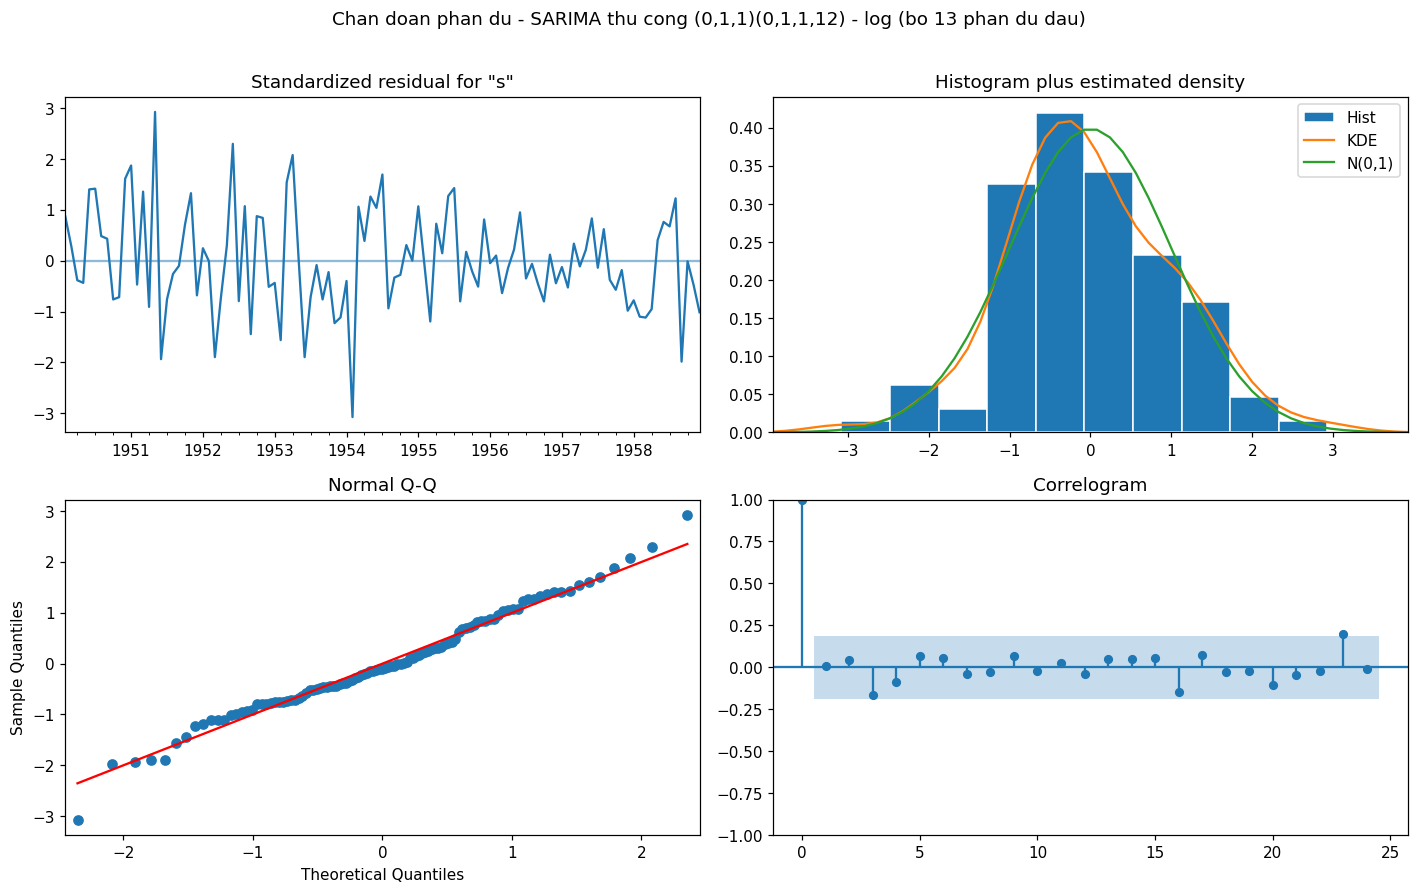

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.3423      0.087     -3.921      0.000      -0.513      -0.171
ma.S.L12      -0.5406      0.105     -5.158      0.000      -0.746      -0.335
sigma2         0.0014      0.000      7.866      0.000       0.001       0.002


In [7]:
final = man["thu_cong"]
T.save_model(final["_fit"], train, (0, 1, 1), (0, 1, 1))
lb = T.run_residuals(final)
display(lb); print(lb.attrs)
display(Image(R / "residual_diagnostics.png"))
print(final["_fit"].summary().tables[1])

**Đọc kết quả:**

* **Ljung-Box p = 0,56 / 0,91 / 0,91 / 0,80** ở lag 6 / 12 / 18 / 24, đều > 0,05: **không** bác bỏ "phần dư là nhiễu
  trắng". Mô hình đã bắt hết cấu trúc tự tương quan ✅. Correlogram: không lag nào vượt dải, kể cả lag 12 và 24.
* **Phân phối:** Jarque-Bera p = 0,58 (không bác bỏ chuẩn), độ lệch 0,17, độ nhọn 3,36. Q-Q bám đường thẳng, chỉ hơi lệch
  ở 2 đuôi (1 điểm −3σ năm 1954). Khoảng tin cậy dựa trên giả định chuẩn, nên điều này quan trọng.
* Độ lệch chuẩn phần dư trên log = 0,039 → sai số 1 tháng tới ≈ ±3,9%.
* Tham số: θ₁ (MA) = −0,34, Θ₁ (SMA) = −0,54, cả hai có ý nghĩa thống kê (p ≤ 0,0001).
* ⚠️ Phần dư chuẩn hoá trông **hẹp dần** sau 1955: phương sai trên log có thể vẫn giảm theo thời gian, khớp với nhận xét
  "log chưa ổn định hoàn toàn" ở bước 1–3.

## 11–13. Dự báo 24 tháng + khoảng tin cậy, MAPE, tỉ lệ phủ

,mo_hinh,MAPE_%,MAE,RMSE,sai_lech_TB_%,phu_95_%,phu_80_%
0,Naive (thang truoc),23.5775,115.2500,137.3290,-23.5775,NaN,NaN
1,Seasonal naive (cung thang nam ngoai),15.5234,71.2500,76.9946,-15.5234,NaN,NaN
2,Seasonal naive + drift (them),3.0056,13.2788,17.0159,1.2414,NaN,NaN
3,"SARIMA thu cong (0,1,1)(0,1,1,12) - log",8.5154,39.4431,43.1793,-8.5154,100.0000,95.8333


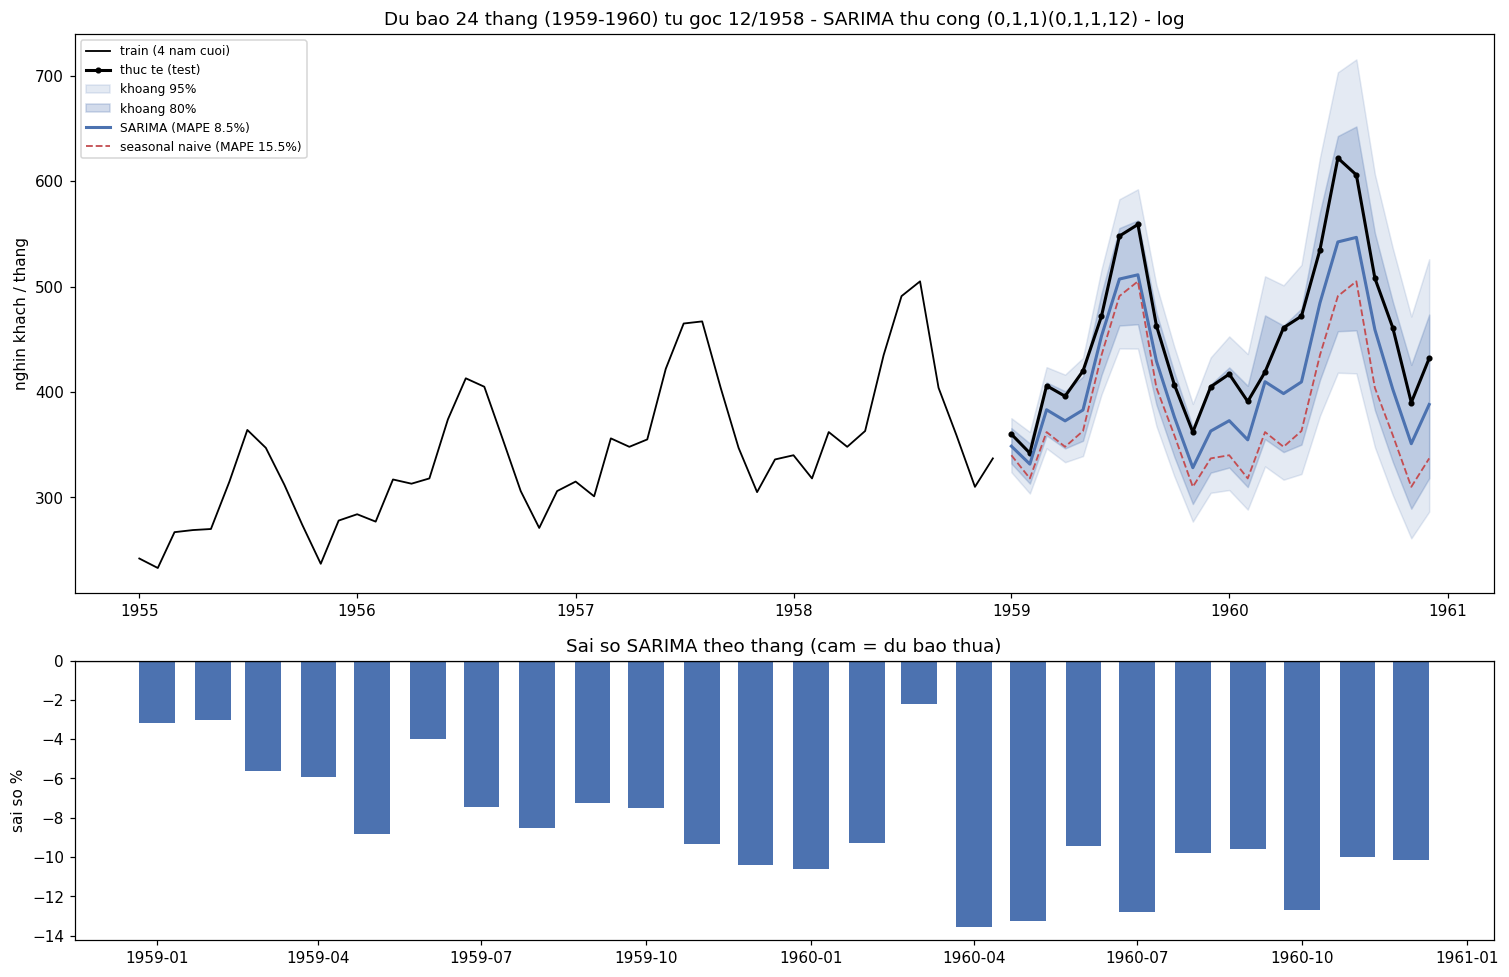

,du_bao,duoi_95,tren_95,duoi_80,tren_80,thuc_te,seasonal_naive,trong_95
1960-07-01,542.4000,418.3000,703.4000,457.7000,642.9000,622.0000,491.0000,True
1960-08-01,546.7000,417.7000,715.6000,458.5000,652.0000,606.0000,505.0000,True
1960-09-01,459.2000,347.7000,606.6000,382.8000,550.9000,508.0000,404.0000,True
1960-10-01,402.6000,302.1000,536.5000,333.7000,485.7000,461.0000,359.0000,True
1960-11-01,350.9000,261.1000,471.6000,289.3000,425.8000,390.0000,310.0000,True
1960-12-01,388.2000,286.5000,526.0000,318.2000,473.5000,432.0000,337.0000,True


In [8]:
comp = T.run_forecast(y, train, test, final, base)
display(comp)
display(Image(R / "du_bao_khoang.png"))
display(pd.read_csv(R / "du_bao_24_thang.csv", index_col=0).tail(6))

**Đọc kết quả (test 1959–1960, dự báo 24 tháng một lần):**

| | MAPE | MAE (nghìn khách) | Sai lệch TB | Phủ 95% | Phủ 80% |
|---|---:|---:|---:|---:|---:|
| Naive | 23,6% | 115 | −23,6% | — | — |
| Seasonal naive | 15,5% | 71 | −15,5% | — | — |
| **SARIMA(0,1,1)(0,1,1,12) log** | **8,5%** | **39** | −8,5% | **100%** | **95,8%** |
| (thêm) Seasonal naive + drift | 3,0% | 13 | +1,2% | — | — |

* ✅ **SARIMA thắng cả 2 baseline bắt buộc**: giảm 45% sai số so với seasonal naive.
* **Dự báo thiếu ở cả 24 tháng** (−2% đến −13,5%): 1959–1960 tăng nhanh hơn xu hướng trung bình 1949–1958 mà mô hình học
  được. MAPE 8,5% **cao hơn mức tham chiếu 3–5%** của đề cho dự báo 24 tháng một lần. Mức 3–5% khớp với dự báo **1 tháng
  tới** (bên dưới: 2,6%).
* ⭐ **Tỉ lệ phủ:** **24/24 (100%)** giá trị thật nằm trong khoảng 95%, và 23/24 (95,8%) nằm trong khoảng 80%. Dù tâm dự
  báo lệch thấp, khoảng đủ rộng để chứa thực tế. Khoảng 80% phủ tới 96% cho thấy khoảng **hơi rộng**: an toàn cho lập
  kế hoạch theo kịch bản, nhưng hơi tốn kém nếu chuẩn bị theo cận trên.
* **Ví dụ dùng cho lập kế hoạch:** tháng 12/1960 dự báo **388 nghìn khách**, khoảng 80% **318–474**, khoảng 95%
  **287–526**. Thực tế 432. Khoảng 95% **mở rộng theo tầm dự báo**: 12/1959 là 304–433 (−16% / +19% quanh dự báo), 12/1960 là
  287–526 (−26% / +35%). Đúng như kỳ vọng: càng xa càng bất định.

## Thêm: dự báo cuốn chiếu 1 tháng, và backtest 4 gốc

* **1 tháng tới:** giữ nguyên tham số ước lượng trên train, mỗi tháng của test dùng dữ liệu thật tới tháng trước
  (`fit.apply(log(y))` + `get_prediction(dynamic=False)`).
* **Backtest:** lặp lại toàn bộ quy trình (fit bậc đã chọn, dự báo 24 tháng) từ 4 gốc: 12/1955, 12/1956, 12/1957, 12/1958.

In [9]:
os_ = T.one_step(y, train, test, (0, 1, 1), (0, 1, 1))
display(os_)
bt, bts = T.run_backtest(y, (0, 1, 1), (0, 1, 1))
display(bt.pivot_table(index="goc", columns="mo_hinh", values="MAPE_%", sort=False))
display(bts)
T.save_summary(adf=st["adf"], decompose=look["decompose"], bay_aic=trap, thu_cong=man_t, luoi_top10=grid_t.head(10),
               chon=final["mo_hinh"], ljung_box=lb, ljung_box_attrs=lb.attrs, so_sanh_test=comp, mot_buoc=os_, backtest=bts)

,mo_hinh,MAPE_%,MAE,RMSE,sai_lech_TB_%
0,SARIMA 1 buoc (tham so tu train),2.5525,11.5281,15.2772,-0.3306
1,Naive 1 buoc (thang truoc that),9.7299,44.2083,51.7820,-0.4221
2,Seasonal naive 1 buoc (nam ngoai that),10.5227,47.5833,49.9867,-10.5227


mo_hinh,SARIMA,Naive (thang truoc),Seasonal naive (cung thang nam ngoai),Seasonal naive + drift (them)
goc,,,,
12/1955,2.8314,18.5802,18.1406,2.2792
12/1956,5.9701,16.6327,12.1556,7.8258
12/1957,7.6376,15.9133,8.5203,11.4494
12/1958,8.5154,23.5775,15.5234,3.0056


,MAPE_%,phu_95_%,phu_80_%
mo_hinh,,,
SARIMA,6.2386,98.9583,91.6667
Naive (thang truoc),18.6759,NaN,NaN
Seasonal naive (cung thang nam ngoai),13.5850,NaN,NaN
Seasonal naive + drift (them),6.1400,NaN,NaN


[save] reports/tom_tat.json


**Đọc kết quả:**

**Dự báo 1 tháng tới (test 1959–1960):** SARIMA MAPE **2,6%** (sai lệch TB chỉ −0,3%), so với naive 9,7% và seasonal
naive 10,5%. Đúng mức tham chiếu 3–5% của đề. Khi được cập nhật dữ liệu mới mỗi tháng, mô hình gần như hết lệch.

**Backtest 24 tháng, MAPE theo gốc dự báo:**

| Gốc | SARIMA | Seasonal naive | Naive | SN + drift |
|---|---:|---:|---:|---:|
| 12/1955 | **2,8%** | 18,1% | 18,6% | 2,3% |
| 12/1956 | **6,0%** | 12,2% | 16,6% | 7,8% |
| 12/1957 | **7,6%** | 8,5% | 15,9% | 11,4% |
| 12/1958 | 8,5% | 15,5% | 23,6% | **3,0%** |
| **Trung bình** | **6,2%** | 13,6% | 18,7% | 6,1% |

* ✅ SARIMA **thắng seasonal naive ở cả 4 gốc** (6,2% so với 13,6% trung bình).
* SARIMA và "seasonal naive + drift" **hoà** về trung bình (6,2% / 6,1%), nhưng SARIMA **ổn định hơn**: 2,8–8,5% so với
  2,3–11,4%. Drift cố định thắng khi tốc độ tăng của giai đoạn test giống trung bình lịch sử (1956, 1959–1960), và thua
  đậm khi không giống (1958 tăng chậm: 11,4%).
* **Tỉ lệ phủ gộp 4 gốc (96 tháng):** khoảng 95% phủ **99%**, khoảng 80% phủ **92%**. Khoảng nhất quán **rộng hơn danh
  nghĩa**, an toàn nhưng hơi bảo thủ. Không có trường hợp "khoảng quá hẹp, không dùng được".

## Kết luận

1. **Chuỗi nhân tính → lấy log.** Không log: MAPE 14,4% và khoảng 95% chỉ phủ 50%.
2. **d = D = 1** (ADF p: 0,99 → 0,42 → 0,07 → **0,0002**). ACF tắt sau lag 1 và lag 12 → **SARIMA(0,1,1)(0,1,1,12)**,
   được cả ACF/PACF lẫn lưới AIC chọn.
3. ⚠️ Code mẫu `enforce_*=False` làm AIC so sánh trên **số điểm khác nhau** (93–106), dẫn tới chọn nhầm mô hình không có
   mùa vụ. Dùng mặc định `enforce=True` khi so AIC.
4. Phần dư là nhiễu trắng (Ljung-Box p 0,80–0,91) và gần chuẩn (Jarque-Bera p 0,58).
5. **Dự báo 24 tháng:** MAPE 8,5% (seasonal naive 15,5%), khoảng 95% phủ 100%. **1 tháng tới:** MAPE 2,6%.
   **Backtest 4 gốc:** 6,2% (seasonal naive 13,6%).
6. **Hạn chế:**
   * ARIMA chỉ dùng **quá khứ của chính chuỗi**: không biết khuyến mãi, ngày lễ, giá vé, kinh tế. Năm 1959–1960 tăng
     nhanh bất thường, nên mô hình dự báo thiếu suốt 24 tháng. Cần SARIMAX với biến ngoài hoặc ML + lag (TT-31).
   * `exp()` của dự báo trên log cho **trung vị**, không phải trung bình (thấp hơn trung bình ~σ²/2 ≈ 0,1% với 1 tháng,
     lớn dần theo tầm dự báo).
   * Giả định cấu trúc **không đổi**: một cú sốc (dịch bệnh, đổi chính sách) làm hỏng toàn bộ mô hình.
   * Một baseline rất đơn giản (seasonal naive + drift) **ngang** SARIMA về trung bình. Giá trị thêm của SARIMA là sự ổn
     định giữa các giai đoạn và **khoảng dự báo** có cơ sở.